# Shortest Path Search on the Wikispeedia Graph


## 1. Setup

In [1]:
import gc
import heapq
import random
import statistics
import tarfile
import time
import tracemalloc
import urllib.request
from collections import deque
from dataclasses import dataclass
from pathlib import Path
from typing import Optional
from urllib.parse import unquote

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd

NOTEBOOK_START = time.perf_counter()
SEED = 42

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "wikispeedia_paths-and-graph"
RESULTS_DIR = ROOT / "results"
FIGURES_DIR = RESULTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print("numpy", np.__version__, "| pandas", pd.__version__, "| networkx", nx.__version__)

numpy 2.4.6 | pandas 2.2.3 | networkx 3.7


In [2]:
URL = "https://snap.stanford.edu/data/wikispeedia/wikispeedia_paths-and-graph.tar.gz"
ARCHIVE = ROOT / "wikispeedia_paths-and-graph.tar.gz"

if not DATA_DIR.exists():
    if not ARCHIVE.exists():
        print("Downloading the dataset...")
        urllib.request.urlretrieve(URL, ARCHIVE)
    with tarfile.open(ARCHIVE) as tar:
        tar.extractall(ROOT / "data", filter="data")

for f in sorted(DATA_DIR.iterdir()):
    print(f"{f.name:40s} {f.stat().st_size / 1e6:5.1f} MB")

articles.tsv                               0.1 MB
categories.tsv                             0.3 MB
links.tsv                                  3.1 MB
paths_finished.tsv                         5.6 MB
paths_unfinished.tsv                       2.7 MB
shortest-path-distance-matrix.txt         21.2 MB


In [3]:
def peek(filename, n=3):
    print(f"--- {filename} ---")
    shown = 0
    with open(DATA_DIR / filename, encoding="utf-8") as f:
        for line in f:
            if line.strip() and not line.startswith("#"):
                print(line.rstrip()[:150])
                shown += 1
                if shown == n:
                    break
    print()

peek("articles.tsv")
peek("links.tsv")
peek("categories.tsv")
peek("paths_finished.tsv")

--- articles.tsv ---
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in
%C3%85land
%C3%89douard_Manet

--- links.tsv ---
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in	Bede
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in	Columba
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in	D%C3%A1l_Riata

--- categories.tsv ---
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in	subject.History.British_History.British_History_1500_and_before_including_Roman_Britain
%C3%81ed%C3%A1n_mac_Gabr%C3%A1in	subject.People.Historical_figures
%C3%85land	subject.Countries

--- paths_finished.tsv ---
6a3701d319fc3754	1297740409	166	14th_century;15th_century;16th_century;Pacific_Ocean;Atlantic_Ocean;Accra;Africa;Atlantic_slave_trade;African_slave_tr
3824310e536af032	1344753412	88	14th_century;Europe;Africa;Atlantic_slave_trade;African_slave_trade	3
415612e93584d30e	1349298640	138	14th_century;Niger;Nigeria;British_Empire;Slavery;Africa;Atlantic_slave_trade;African_slave_trade	NULL



## 2. Data Processing

The problem is modelled as a graph search:

- **State:** the current article
- **Action:** clicking a link on that article
- **Cost:** 1 per click
- **Goal:** reaching the target article

Links are one-way, so the graph is directed.

In [4]:
@dataclass
class Graph:
    names: list        # article id -> article name
    index: dict        # article name -> article id
    out_edges: list    # article id -> articles it links to
    in_edges: list     # article id -> articles that link to it
    categories: list   # article id -> list of category paths

    @property
    def n_nodes(self):
        return len(self.names)

    @property
    def n_edges(self):
        return sum(len(t) for t in self.out_edges)


def _data_lines(path):
    # read a file, skipping empty lines and '#' comment lines
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.rstrip("\n")
            if line and not line.startswith("#"):
                yield line


def load_graph(data_dir):
    names = [unquote(line) for line in _data_lines(data_dir / "articles.tsv")]
    index = {name: i for i, name in enumerate(names)}

    out_sets = [set() for _ in names]
    for line in _data_lines(data_dir / "links.tsv"):
        source, target = (unquote(x) for x in line.split("\t"))
        if source != target:   # drop self-links
            out_sets[index[source]].add(index[target])

    in_sets = [set() for _ in names]
    for source, targets in enumerate(out_sets):
        for target in targets:
            in_sets[target].add(source)

    categories = [[] for _ in names]
    for line in _data_lines(data_dir / "categories.tsv"):
        article, category = line.split("\t")
        levels = tuple(category.split(".")[1:])   # drop the 'subject' root
        categories[index[unquote(article)]].append(levels)

    return Graph(names, index,
                 [sorted(s) for s in out_sets],
                 [sorted(s) for s in in_sets],
                 categories)


def load_distance_matrix(data_dir):
    # true shortest distances from the dataset; -1 means no path
    rows = list(_data_lines(data_dir / "shortest-path-distance-matrix.txt"))
    raw = np.array([np.frombuffer(row.encode("ascii"), dtype=np.uint8) for row in rows])
    matrix = raw.astype(np.int16) - ord("0")
    matrix[raw == ord("_")] = -1
    return matrix

In [5]:
def resolve_back_clicks(tokens):
    # turn a click trail with '<' (Back) into the path the player actually took
    stack = []
    for token in tokens:
        if token == "<":
            if len(stack) > 1:
                stack.pop()
        else:
            stack.append(token)
    return stack


def load_finished_paths(data_dir, graph):
    rows = []
    skipped = 0
    for line in _data_lines(data_dir / "paths_finished.tsv"):
        _, _, seconds, path, rating = line.split("\t")
        tokens = [unquote(t) for t in path.split(";")]
        if any(t != "<" and t not in graph.index for t in tokens):
            skipped += 1
            continue
        effective = resolve_back_clicks(tokens)
        rows.append({
            "source": graph.index[effective[0]],
            "target": graph.index[effective[-1]],
            "clicks": len(tokens) - 1,          # includes Back clicks
            "back_clicks": tokens.count("<"),
            "effective_length": len(effective) - 1,
            "seconds": int(seconds),
            "rating": None if rating == "NULL" else int(rating),
        })
    return pd.DataFrame(rows), skipped


print(resolve_back_clicks(["A", "B", "<", "C", "D", "<", "<", "E"]))

['A', 'E']


In [6]:
load_start = time.perf_counter()
graph = load_graph(DATA_DIR)
matrix = load_distance_matrix(DATA_DIR)
paths, skipped_paths = load_finished_paths(DATA_DIR, graph)
LOAD_SECONDS = time.perf_counter() - load_start

print(f"Articles: {graph.n_nodes:,}")
print(f"Links:    {graph.n_edges:,}")
print(f"Games:    {len(paths):,} (skipped {skipped_paths})")
print(f"Distance matrix: {matrix.shape[0]:,} x {matrix.shape[1]:,}")
print(f"Loading time: {LOAD_SECONDS:.2f} s")

Articles: 4,604
Links:    119,772
Games:    51,318 (skipped 0)
Distance matrix: 4,604 x 4,604
Loading time: 1.01 s


## 3. Exploring the Graph

In [7]:
raw_links = sum(1 for _ in _data_lines(DATA_DIR / "links.tsv"))
out_degree = np.array([len(x) for x in graph.out_edges])
in_degree = np.array([len(x) for x in graph.in_edges])
reachable = matrix[matrix > 0]

overview = pd.Series({
    "Articles (nodes)": graph.n_nodes,
    "Raw links": raw_links,
    "Self-links removed": raw_links - graph.n_edges,
    "Links after cleaning (edges)": graph.n_edges,
    "Mean links per article": round(out_degree.mean(), 2),
    "Largest out-degree": out_degree.max(),
    "Articles with no outgoing links": (out_degree == 0).sum(),
    "Articles with no incoming links": (in_degree == 0).sum(),
    "Articles with no links at all": ((out_degree == 0) & (in_degree == 0)).sum(),
    "Articles with no category": sum(1 for c in graph.categories if not c),
    "Reachable ordered pairs (%)": round(100 * (matrix[~np.eye(graph.n_nodes, dtype=bool)] > 0).mean(), 2),
    "Mean shortest distance (clicks)": round(reachable.mean(), 3),
    "Longest shortest distance (clicks)": reachable.max(),
}, name="Value")
overview.to_frame()

,Value
Articles (nodes),4604.000
Raw links,119882.000
Self-links removed,110.000
Links after cleaning (edges),119772.000
Mean links per article,26.010
Largest out-degree,294.000
Articles with no outgoing links,17.000
Articles with no incoming links,474.000
Articles with no links at all,12.000
Articles with no category,6.000


In [8]:
top = np.argsort(-in_degree)[:5]
pd.DataFrame({"article": [graph.names[i] for i in top], "incoming_links": in_degree[top]})

,article,incoming_links
0,United_States,1551
1,United_Kingdom,972
2,France,959
3,Europe,933
4,World_War_II,751


In [9]:
paths[["clicks", "back_clicks", "effective_length", "seconds"]].describe().round(2)

,clicks,back_clicks,effective_length,seconds
count,51318.00,51318.00,51318.00,51318.00
mean,5.76,0.40,4.96,158.28
std,4.68,1.45,3.29,360.84
min,0.00,0.00,0.00,0.00
25%,4.00,0.00,3.00,60.00
50%,5.00,0.00,4.00,107.00
75%,7.00,0.00,6.00,183.00
max,434.00,45.00,404.00,35091.00


## 4. Test Pairs

Test pairs are taken from the human games and split into three separate sets:

- **Validation:** 300 pairs, used only to choose heuristic settings
- **Test:** 1,000 pairs, used for the final results
- **Unreachable:** 200 pairs with no path, used to check completeness

In [10]:
def sample_pairs(paths, matrix, n_test, n_validation, n_unreachable, seed):
    rng = np.random.default_rng(seed)
    pairs = paths[["source", "target"]].drop_duplicates()
    pairs = pairs[pairs["source"] != pairs["target"]]
    pairs = pairs[matrix[pairs["source"].to_numpy(), pairs["target"].to_numpy()] > 0]
    order = rng.permutation(len(pairs))
    shuffled = pairs.iloc[order][["source", "target"]].to_numpy().tolist()
    validation = [tuple(p) for p in shuffled[:n_validation]]
    test = [tuple(p) for p in shuffled[n_validation:n_validation + n_test]]

    sources, targets = np.where(matrix == -1)
    picks = rng.choice(len(sources), size=n_unreachable, replace=False)
    unreachable = [(int(sources[i]), int(targets[i])) for i in picks]
    return validation, test, unreachable


validation_pairs, test_pairs, unreachable_pairs = sample_pairs(
    paths, matrix, n_test=1000, n_validation=300, n_unreachable=200, seed=SEED)

test_distances = np.array([matrix[s, t] for s, t in test_pairs])
distance_table = pd.Series(test_distances).value_counts().sort_index().rename("test_pairs")
distance_table.index.name = "shortest_distance"
distance_table.to_frame().T

shortest_distance,1,2,3,4,5
test_pairs,23,310,514,142,11


## 5. Search Algorithms

Each algorithm is tried on one example pair, **Linux → Double-decker bus**, before the full experiment.

In [11]:
@dataclass
class SearchResult:
    path: Optional[list]   # article ids from source to target, or None if no path
    expanded: int          # nodes whose links were explored
    edges_scanned: int     # links looked at
    max_stored: int        # most nodes kept in memory at once

    @property
    def cost(self):
        return None if self.path is None else len(self.path) - 1


def _build_path(parents, node):
    # follow parent links back to the start, then reverse
    path = [node]
    while parents[node] is not None:
        node = parents[node]
        path.append(node)
    path.reverse()
    return path


def run_example(name, search, source_name, target_name):
    s, t = graph.index[source_name], graph.index[target_name]
    start = time.perf_counter()
    result = search(s, t)
    ms = (time.perf_counter() - start) * 1000
    print(name)
    print("  Path:", " → ".join(graph.names[i] for i in result.path))
    print(f"  Clicks: {result.cost} (shortest: {matrix[s, t]})")
    print(f"  Nodes expanded: {result.expanded:,} | links scanned: {result.edges_scanned:,} | time: {ms:.3f} ms")


EXAMPLE = ("Linux", "Double-decker_bus")

### 5.1 Breadth-First Search (BFS)

BFS is not one of the assigned algorithms. Since every click costs 1, it always finds a shortest path, so it is used as the reference.

In [12]:
def bfs(graph, source, target):
    if source == target:
        return SearchResult([source], 0, 0, 1)
    parents = {source: None}
    frontier = deque([source])
    expanded = edges = 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        for neighbour in graph.out_edges[node]:
            edges += 1
            if neighbour not in parents:
                parents[neighbour] = node
                if neighbour == target:
                    return SearchResult(_build_path(parents, target), expanded, edges, len(parents))
                frontier.append(neighbour)
    return SearchResult(None, expanded, edges, len(parents))


run_example("BFS", lambda s, t: bfs(graph, s, t), *EXAMPLE)

BFS
  Path: Linux → C++ → Library → 19th_century → London_Underground → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 1,837 | links scanned: 66,790 | time: 9.657 ms


### 5.2 Bidirectional BFS

Two BFS searches run at the same time: one forward from the source, and one backward from the target over reversed links. The search stops when they meet. Each turn expands one full level of the smaller side.

In [13]:
def bidirectional_bfs(graph, source, target):
    if source == target:
        return SearchResult([source], 0, 0, 1)
    parents_f, parents_b = {source: None}, {target: None}
    frontier_f, frontier_b = [source], [target]
    expanded = edges = 0

    while frontier_f and frontier_b:
        forward = len(frontier_f) <= len(frontier_b)   # expand the smaller side
        frontier = frontier_f if forward else frontier_b
        adjacency = graph.out_edges if forward else graph.in_edges
        visited, other = (parents_f, parents_b) if forward else (parents_b, parents_f)

        next_frontier = []
        for node in frontier:
            expanded += 1
            for neighbour in adjacency[node]:
                edges += 1
                if neighbour in visited:
                    continue
                visited[neighbour] = node
                if neighbour in other:   # the two searches meet
                    head = _build_path(parents_f, neighbour)
                    tail = _build_path(parents_b, neighbour)
                    tail.reverse()
                    stored = len(parents_f) + len(parents_b)
                    return SearchResult(head + tail[1:], expanded, edges, stored)
                next_frontier.append(neighbour)

        if forward:
            frontier_f = next_frontier
        else:
            frontier_b = next_frontier

    return SearchResult(None, expanded, edges, len(parents_f) + len(parents_b))


run_example("Bidirectional BFS", lambda s, t: bidirectional_bfs(graph, s, t), *EXAMPLE)

Bidirectional BFS
  Path: Linux → C++ → Library → 19th_century → London_Underground → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 21 | links scanned: 376 | time: 0.239 ms


### 5.3 A* Search

A* always expands the node with the lowest f(n) = g(n) + h(n), where g(n) is the clicks so far and h(n) is an estimate of the clicks left. If h never overestimates, A* finds a shortest path. With h = 0 it has no guidance, so this is used as the baseline.

In [14]:
def astar(graph, source, target, heuristic):
    best_g = {source: 0}
    parents = {source: None}
    frontier = [(heuristic(source), 0, source)]   # (f, -g, node)
    expanded = edges = 0
    max_stored = 1

    while frontier:
        _, negative_g, node = heapq.heappop(frontier)
        g = -negative_g
        if g > best_g[node]:
            continue   # old queue entry, skip it
        if node == target:
            return SearchResult(_build_path(parents, target), expanded, edges, max_stored)
        expanded += 1
        for neighbour in graph.out_edges[node]:
            edges += 1
            new_g = g + 1
            if new_g < best_g.get(neighbour, float("inf")):
                best_g[neighbour] = new_g
                parents[neighbour] = node
                heapq.heappush(frontier, (new_g + heuristic(neighbour), -new_g, neighbour))
        max_stored = max(max_stored, len(best_g) + len(frontier))
    return SearchResult(None, expanded, edges, max_stored)


def zero_heuristic(target):
    return lambda node: 0


run_example("A* (no heuristic)", lambda s, t: astar(graph, s, t, zero_heuristic(t)), *EXAMPLE)

A* (no heuristic)
  Path: Linux → C++ → Library → 19th_century → London_Underground → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 3,561 | links scanned: 103,896 | time: 175.192 ms


## 6. Heuristics for A*

Wikipedia articles have no coordinates, so there is no straight-line distance to use. Two heuristics are designed instead.

### 6.1 Landmark Heuristic

A few landmark articles are chosen, and the distance from every article to and from each landmark is computed in advance. The triangle inequality then gives a lower bound on the distance left. For landmark L, the distance from n to target t is at least d(L, t) − d(L, n) and at least d(n, L) − d(t, L). The heuristic never overestimates, so A* stays optimal.

In [15]:
def bfs_distances(adjacency, source):
    # distance from source to every node, None if unreachable
    distances = [None] * len(adjacency)
    distances[source] = 0
    queue = deque([source])
    while queue:
        node = queue.popleft()
        for neighbour in adjacency[node]:
            if distances[neighbour] is None:
                distances[neighbour] = distances[node] + 1
                queue.append(neighbour)
    return distances


def largest_scc(graph):
    # biggest group of articles where every article can reach every other
    g = nx.DiGraph()
    g.add_nodes_from(range(graph.n_nodes))
    g.add_edges_from((u, v) for u, targets in enumerate(graph.out_edges) for v in targets)
    return max(nx.strongly_connected_components(g), key=len)


def select_landmarks(graph, k, strategy):
    # 'hub': most-linked articles. 'farthest': spread the landmarks far apart
    scc = largest_scc(graph)
    degree = lambda n: (len(graph.out_edges[n]) + len(graph.in_edges[n]), -n)
    by_degree = sorted(scc, key=degree, reverse=True)
    if strategy == "hub":
        return by_degree[:k]
    landmarks = [by_degree[0]]
    nearest = {n: float("inf") for n in scc}
    while len(landmarks) < k:
        forward = bfs_distances(graph.out_edges, landmarks[-1])
        backward = bfs_distances(graph.in_edges, landmarks[-1])
        for n in scc:
            nearest[n] = min(nearest[n], forward[n] + backward[n])
        landmarks.append(max(scc, key=lambda n: (nearest[n], degree(n))))
    return landmarks


class LandmarkHeuristic:
    def __init__(self, graph, landmarks):
        self.landmarks = list(landmarks)
        self.from_landmark = [bfs_distances(graph.out_edges, L) for L in self.landmarks]
        self.to_landmark = [bfs_distances(graph.in_edges, L) for L in self.landmarks]

    def __call__(self, target):
        tables = []
        for from_l, to_l in zip(self.from_landmark, self.to_landmark):
            if from_l[target] is not None:
                tables.append((from_l, from_l[target], 1))
            if to_l[target] is not None:
                tables.append((to_l, to_l[target], -1))

        def h(node):
            best = 0
            for table, target_value, sign in tables:
                value = table[node]
                if value is not None:
                    bound = sign * (target_value - value)
                    if bound > best:
                        best = bound
            return best
        return h


start = time.perf_counter()
example_landmarks = select_landmarks(graph, 16, "farthest")
example_landmark_h = LandmarkHeuristic(graph, example_landmarks)
print(f"Setup time: {time.perf_counter() - start:.2f} s")
print("First landmarks:", ", ".join(graph.names[i] for i in example_landmarks[:6]))
print()
run_example("A* (landmarks)", lambda s, t: astar(graph, s, t, example_landmark_h(t)), *EXAMPLE)

Setup time: 0.95 s
First landmarks: United_States, Mistle_Thrush, Gray_reef_shark, Great_Comet_of_1882, Swallow, Wren

A* (landmarks)
  Path: Linux → Richard_Stallman → Winston_Churchill → William_Ewart_Gladstone → London_Underground → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 213 | links scanned: 5,260 | time: 17.829 ms


### 6.2 Category Heuristic

Each article belongs to categories in a tree, such as Science > Physics. The heuristic is h = w × (1 − similarity), where similarity measures how much of the category path two articles share. With w = 1, h is at most 1, so it never overestimates. Larger w searches less but may return longer paths.

In [16]:
class CategoryHeuristic:
    def __init__(self, graph, weight):
        self.graph = graph
        self.weight = weight

    @staticmethod
    def _similarity(cats_a, cats_b):
        best = 0.0
        for a in cats_a:
            for b in cats_b:
                shared = 0
                for level_a, level_b in zip(a, b):
                    if level_a != level_b:
                        break
                    shared += 1
                best = max(best, 2 * shared / (len(a) + len(b)))
        return best

    def __call__(self, target):
        graph, weight = self.graph, self.weight
        target_cats = graph.categories[target]
        cache = {}

        def h(node):
            if node == target:
                return 0.0
            key = tuple(graph.categories[node])
            if key not in cache:
                cache[key] = weight * (1 - self._similarity(key, target_cats))
            return cache[key]
        return h


for w in (1, 2):
    category_h = CategoryHeuristic(graph, w)
    run_example(f"A* (category, w={w})", lambda s, t: astar(graph, s, t, category_h(t)), *EXAMPLE)
    print()

A* (category, w=1)
  Path: Linux → Richard_Stallman → Automobile → MINI_(BMW) → Mini → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 1,426 | links scanned: 54,416 | time: 22.372 ms

A* (category, w=2)
  Path: Linux → Richard_Stallman → Automobile → MINI_(BMW) → Mini → Double-decker_bus
  Clicks: 5 (shortest: 5)
  Nodes expanded: 118 | links scanned: 4,023 | time: 3.514 ms



## 7. Correctness Checks

Before measuring performance, the implementations are checked against the dataset's distance matrix and against networkx.

In [17]:
rng = random.Random(SEED)

# 1. BFS distances match the dataset's distance matrix
for source in rng.sample(range(graph.n_nodes), 100):
    mine = [-1 if d is None else d for d in bfs_distances(graph.out_edges, source)]
    assert mine == matrix[source].tolist()
print("BFS matches the distance matrix for 100 source articles")

# 2. The landmark heuristic never overestimates
check_h = LandmarkHeuristic(graph, select_landmarks(graph, 8, "farthest"))
for target in rng.sample(range(graph.n_nodes), 100):
    h = check_h(target)
    assert all(h(n) <= matrix[n, target] for n in range(graph.n_nodes) if matrix[n, target] >= 0)
print("Landmark heuristic never overestimated for 100 target articles")

# 3. Bidirectional BFS and A* match networkx on small random graphs
checked = 0
for seed in range(20):
    r = random.Random(seed)
    n = 40
    out_e = [[v for v in range(n) if v != u and r.random() < 0.05] for u in range(n)]
    in_e = [[u for u in range(n) if v in out_e[u]] for v in range(n)]
    small = Graph([str(i) for i in range(n)], {}, out_e, in_e, [[] for _ in range(n)])
    nxg = nx.DiGraph((u, v) for u in range(n) for v in out_e[u])
    nxg.add_nodes_from(range(n))
    truth = dict(nx.all_pairs_shortest_path_length(nxg))
    for s in range(n):
        for t in range(n):
            expected = truth[s].get(t)
            assert bidirectional_bfs(small, s, t).cost == expected
            assert astar(small, s, t, zero_heuristic(t)).cost == expected
            checked += 1
print(f"Bidirectional BFS and A* matched networkx on {checked:,} pairs")

BFS matches the distance matrix for 100 source articles
Landmark heuristic never overestimated for 100 target articles
Bidirectional BFS and A* matched networkx on 32,000 pairs


## 8. Evaluation

Every algorithm runs on the same 1,000 test pairs. **Accuracy** is the percentage of pairs where the algorithm returns a valid path of the true shortest length. Runtime is the median of 3 runs per pair. Peak memory is measured in a separate pass, because memory tracing slows the code down.

In [18]:
def is_valid_path(graph, path, source, target):
    if not path or path[0] != source or path[-1] != target:
        return False
    return all(b in graph.out_edges[a] for a, b in zip(path, path[1:]))


def evaluate(graph, name, search, pairs, distances, repeats=3):
    rows = []
    gc.disable()
    try:
        for source, target in pairs:
            times = []
            for _ in range(repeats):
                start = time.perf_counter()
                result = search(source, target)
                times.append(time.perf_counter() - start)
            true_distance = int(distances[source, target])
            found = result.path is not None
            rows.append({
                "algorithm": name,
                "source": source,
                "target": target,
                "true_distance": true_distance,
                "found": found,
                "cost": result.cost,
                "optimal": found and result.cost == true_distance,
                "valid": found and is_valid_path(graph, result.path, source, target),
                "expanded": result.expanded,
                "edges_scanned": result.edges_scanned,
                "max_stored": result.max_stored,
                "time_ms": statistics.median(times) * 1000,
            })
    finally:
        gc.enable()
    return pd.DataFrame(rows)


def peak_memory_kib(search, pairs):
    peaks = []
    tracemalloc.start()
    try:
        for source, target in pairs:
            tracemalloc.reset_peak()
            before = tracemalloc.get_traced_memory()[0]
            result = search(source, target)
            peaks.append(tracemalloc.get_traced_memory()[1] - before)
            del result
    finally:
        tracemalloc.stop()
    return sum(peaks) / len(peaks) / 1024


def summarise(results):
    results = results.assign(extra_clicks=results["cost"] - results["true_distance"])
    return results.groupby("algorithm", sort=False).agg(
        accuracy_pct=("optimal", lambda s: 100 * s.mean()),
        found_pct=("found", lambda s: 100 * s.mean()),
        valid_pct=("valid", lambda s: 100 * s.mean()),
        mean_path_length=("cost", "mean"),
        mean_extra_clicks=("extra_clicks", "mean"),
        max_extra_clicks=("extra_clicks", "max"),
        mean_expanded=("expanded", "mean"),
        mean_edges_scanned=("edges_scanned", "mean"),
        mean_max_stored=("max_stored", "mean"),
        mean_time_ms=("time_ms", "mean"),
        median_time_ms=("time_ms", "median"),
        p95_time_ms=("time_ms", lambda s: s.quantile(0.95)),
        total_time_s=("time_ms", lambda s: s.sum() / 1000),
    )

### 8.1 Choosing Heuristic Settings

Settings are chosen on the validation pairs only. For landmarks, 4, 8 and 16 landmarks are tried with both strategies, keeping the one that expands the fewest nodes. For the category heuristic, w = 1 is kept because it is admissible, and the largest weight with at least 70% accuracy is kept as the inadmissible option.

In [19]:
def astar_with(factory):
    return lambda source, target: astar(graph, source, target, factory(target))

sweep_rows = []
landmark_options = {}
for strategy in ("hub", "farthest"):
    for k in (4, 8, 16):
        start = time.perf_counter()
        heuristic = LandmarkHeuristic(graph, select_landmarks(graph, k, strategy))
        setup = time.perf_counter() - start
        landmark_options[(strategy, k)] = (heuristic, setup)
        result = evaluate(graph, f"{strategy}, k={k}", astar_with(heuristic), validation_pairs, matrix, repeats=1)
        row = summarise(result).iloc[0]
        sweep_rows.append({"heuristic": "landmark", "setting": f"{strategy}, k={k}", "strategy": strategy, "k": k,
                           "accuracy_pct": row.accuracy_pct, "mean_extra_clicks": row.mean_extra_clicks,
                           "mean_expanded": row.mean_expanded, "mean_time_ms": row.mean_time_ms, "setup_s": setup})

for w in (1, 2, 3, 4, 6, 8):
    result = evaluate(graph, f"w={w}", astar_with(CategoryHeuristic(graph, w)), validation_pairs, matrix, repeats=1)
    row = summarise(result).iloc[0]
    sweep_rows.append({"heuristic": "category", "setting": f"w={w}", "w": w,
                       "accuracy_pct": row.accuracy_pct, "mean_extra_clicks": row.mean_extra_clicks,
                       "mean_expanded": row.mean_expanded, "mean_time_ms": row.mean_time_ms, "setup_s": 0.0})

sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS_DIR / "validation_sweep.csv", index=False)

best_landmark = sweep[sweep.heuristic == "landmark"].sort_values("mean_expanded").iloc[0]
BEST_STRATEGY, BEST_K = best_landmark.strategy, int(best_landmark.k)
category_rows = sweep[sweep.heuristic == "category"]
RISKY_W = int(category_rows[category_rows.accuracy_pct >= 70].w.max())

print(f"Chosen landmarks: {BEST_STRATEGY}, k={BEST_K} | chosen category weight: w={RISKY_W}")
sweep[["heuristic", "setting", "accuracy_pct", "mean_extra_clicks", "mean_expanded", "mean_time_ms", "setup_s"]].round(3)

Chosen landmarks: farthest, k=16 | chosen category weight: w=2


,heuristic,setting,accuracy_pct,mean_extra_clicks,mean_expanded,mean_time_ms,setup_s
0,landmark,"hub, k=4",100.000,0.000,303.020,5.170,0.239
1,landmark,"hub, k=8",100.000,0.000,198.190,4.936,0.287
2,landmark,"hub, k=16",100.000,0.000,121.020,6.043,0.334
3,landmark,"farthest, k=4",100.000,0.000,303.787,5.296,0.278
4,landmark,"farthest, k=8",100.000,0.000,168.973,8.841,0.480
5,landmark,"farthest, k=16",100.000,0.000,93.813,5.289,0.665
6,category,w=1,100.000,0.000,251.470,4.812,0.000
7,category,w=2,77.000,0.230,109.077,2.501,0.000
8,category,w=3,63.667,0.380,83.863,2.193,0.000
9,category,w=4,50.000,0.630,77.777,1.909,0.000


### 8.2 Final Experiment

In [20]:
landmark_h, LANDMARK_SETUP_S = landmark_options[(BEST_STRATEGY, BEST_K)]

NAME_BFS = "BFS (reference)"
NAME_BI = "Bidirectional BFS"
NAME_A0 = "A* (no heuristic)"
NAME_AL = "A* (landmarks)"
NAME_C1 = "A* (category, w=1)"
NAME_CW = f"A* (category, w={RISKY_W})"

algorithms = {
    NAME_BFS: lambda s, t: bfs(graph, s, t),
    NAME_BI: lambda s, t: bidirectional_bfs(graph, s, t),
    NAME_A0: astar_with(zero_heuristic),
    NAME_AL: astar_with(landmark_h),
    NAME_C1: astar_with(CategoryHeuristic(graph, 1)),
    NAME_CW: astar_with(CategoryHeuristic(graph, RISKY_W)),
}

experiment_start = time.perf_counter()
results = pd.concat([evaluate(graph, name, search, test_pairs, matrix, repeats=3)
                     for name, search in algorithms.items()], ignore_index=True)

summary = summarise(results)
summary["peak_memory_kib"] = [peak_memory_kib(search, test_pairs) for search in algorithms.values()]
summary["setup_s"] = [LANDMARK_SETUP_S if name == NAME_AL else 0.0 for name in summary.index]

unreachable_rows = []
for name, search in algorithms.items():
    outcome = evaluate(graph, name, search, unreachable_pairs, matrix, repeats=1)
    unreachable_rows.append({"algorithm": name,
                             "correctly_reported_no_path_pct": 100 * (~outcome.found).mean(),
                             "mean_expanded": outcome.expanded.mean(),
                             "mean_time_ms": outcome.time_ms.mean()})
unreachable = pd.DataFrame(unreachable_rows).set_index("algorithm")

EXPERIMENT_SECONDS = time.perf_counter() - experiment_start
results.to_csv(RESULTS_DIR / "per_pair_results.csv", index=False)
summary.to_csv(RESULTS_DIR / "metrics.csv")
unreachable.to_csv(RESULTS_DIR / "unreachable.csv")
print(f"Experiment time: {EXPERIMENT_SECONDS:.1f} s")

Experiment time: 324.7 s


## 9. Results

### 9.1 Overall Performance

In [21]:
columns = {
    "accuracy_pct": "Accuracy (%)",
    "mean_path_length": "Mean path (clicks)",
    "mean_extra_clicks": "Mean extra clicks",
    "mean_expanded": "Nodes expanded",
    "mean_edges_scanned": "Links scanned",
    "mean_max_stored": "Nodes stored",
    "peak_memory_kib": "Peak memory (KiB)",
    "mean_time_ms": "Mean time (ms)",
    "median_time_ms": "Median time (ms)",
    "total_time_s": "Total time, 1,000 pairs (s)",
    "setup_s": "Setup (s)",
}
summary[list(columns)].rename(columns=columns).round(3)

,Accuracy (%),Mean path (clicks),Mean extra clicks,Nodes expanded,Links scanned,Nodes stored,Peak memory (KiB),Mean time (ms),Median time (ms),"Total time, 1,000 pairs (s)",Setup (s)
algorithm,,,,,,,,,,,
BFS (reference),100.0,2.808,0.000,304.606,12593.683,1492.300,95.906,1.684,0.509,1.684,0.000
Bidirectional BFS,100.0,2.808,0.000,4.789,150.798,136.207,7.972,0.030,0.022,0.030,0.000
A* (no heuristic),100.0,2.808,0.000,1558.195,52600.124,5099.703,345.103,16.795,14.649,16.795,0.000
A* (landmarks),100.0,2.808,0.000,90.182,3368.101,1894.973,96.941,5.797,4.244,5.797,0.665
"A* (category, w=1)",100.0,2.808,0.000,295.916,12197.147,2933.766,201.355,5.657,3.493,5.657,0.000
"A* (category, w=2)",81.3,2.995,0.187,136.100,5379.173,2073.083,135.360,3.340,1.839,3.340,0.000


### 9.2 Completeness on Unreachable Pairs

In [22]:
unreachable.round(3)

,correctly_reported_no_path_pct,mean_expanded,mean_time_ms
algorithm,,,
BFS (reference),100.0,3832.125,16.919
Bidirectional BFS,100.0,2.130,0.008
A* (no heuristic),100.0,3832.125,27.513
A* (landmarks),100.0,3832.140,45.013
"A* (category, w=1)",100.0,3832.125,32.878
"A* (category, w=2)",100.0,3841.260,41.884


### 9.3 Results by Path Length

In [23]:
by_distance = (results.groupby(["true_distance", "algorithm"], sort=False)
               .agg(pairs=("optimal", "size"), accuracy_pct=("optimal", lambda s: 100 * s.mean()),
                    mean_expanded=("expanded", "mean"), mean_time_ms=("time_ms", "mean"))
               .reset_index().sort_values(["true_distance", "algorithm"]))
by_distance.to_csv(RESULTS_DIR / "by_distance.csv", index=False)
by_distance.pivot(index="true_distance", columns="algorithm", values="mean_expanded")[list(algorithms)].round(1)

algorithm,BFS (reference),Bidirectional BFS,A* (no heuristic),A* (landmarks),"A* (category, w=1)","A* (category, w=2)"
true_distance,,,,,,
1,1.0,1.0,24.3,1.4,7.3,7.3
2,15.3,2.0,474.9,16.3,38.9,38.2
3,196.9,4.8,1757.0,87.8,211.0,102.5
4,1168.0,10.5,3277.7,262.6,1023.5,422.2
5,2977.2,16.6,3806.6,240.5,2718.3,1043.3


In [24]:
by_distance.pivot(index="true_distance", columns="algorithm", values="accuracy_pct")[list(algorithms)].round(1)

algorithm,BFS (reference),Bidirectional BFS,A* (no heuristic),A* (landmarks),"A* (category, w=1)","A* (category, w=2)"
true_distance,,,,,,
1,100.0,100.0,100.0,100.0,100.0,100.0
2,100.0,100.0,100.0,100.0,100.0,69.7
3,100.0,100.0,100.0,100.0,100.0,84.0
4,100.0,100.0,100.0,100.0,100.0,92.3
5,100.0,100.0,100.0,100.0,100.0,100.0


### 9.4 Example Solution Paths

In [25]:
examples = []
for distance in (2, 3, 4, 5):
    source, target = next((s, t) for s, t in test_pairs if matrix[s, t] == distance)
    for name in (NAME_BI, NAME_AL, NAME_CW):
        path = algorithms[name](source, target).path
        examples.append({"from → to": f"{graph.names[source]} → {graph.names[target]}", "shortest": distance,
                         "algorithm": name, "clicks": len(path) - 1,
                         "path": " → ".join(graph.names[i] for i in path)})
examples = pd.DataFrame(examples)
examples.to_csv(RESULTS_DIR / "example_paths.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(examples)

,from → to,shortest,algorithm,clicks,path
0,Banjul → England,2,Bidirectional BFS,2,Banjul → United_Kingdom → England
1,Banjul → England,2,A* (landmarks),2,Banjul → United_Kingdom → England
2,Banjul → England,2,"A* (category, w=2)",2,Banjul → United_Kingdom → England
3,Tropical_cyclone → Richard_III_of_England,3,Bidirectional BFS,3,Tropical_cyclone → Cape_Verde → 15th_century → Richard_III_of_England
4,Tropical_cyclone → Richard_III_of_England,3,A* (landmarks),3,Tropical_cyclone → English_language → 15th_century → Richard_III_of_England
5,Tropical_cyclone → Richard_III_of_England,3,"A* (category, w=2)",3,Tropical_cyclone → World_War_II → British_Empire → Richard_III_of_England
6,Silicon → George_VI_of_the_United_Kingdom,4,Bidirectional BFS,4,Silicon → Aluminium → Australia → Elizabeth_II_of_the_United_Kingdom → George_VI_of_the_United_Kingdom
7,Silicon → George_VI_of_the_United_Kingdom,4,A* (landmarks),4,Silicon → Antoine_Lavoisier → Law → British_monarchy → George_VI_of_the_United_Kingdom
8,Silicon → George_VI_of_the_United_Kingdom,4,"A* (category, w=2)",4,Silicon → World_War_II → Winston_Churchill → Edward_VIII_of_the_United_Kingdom → George_VI_of_the_United_Kingdom
9,Linux → Double-decker_bus,5,Bidirectional BFS,5,Linux → C++ → Library → 19th_century → London_Underground → Double-decker_bus


### 9.5 Human Players Compared with Shortest Paths

In [26]:
human = paths.merge(pd.DataFrame(test_pairs, columns=["source", "target"]), on=["source", "target"])
human = human.assign(shortest=matrix[human.source.to_numpy(), human.target.to_numpy()])
per_pair = human.groupby(["source", "target"]).agg(
    shortest=("shortest", "first"), games=("clicks", "size"), clicks=("clicks", "mean"),
    effective=("effective_length", "mean"), best_human=("effective_length", "min")).reset_index()
human_by_distance = per_pair.groupby("shortest").agg(
    pairs=("clicks", "size"), human_clicks=("clicks", "mean"), human_effective=("effective", "mean")).round(2)
human_by_distance.to_csv(RESULTS_DIR / "human_comparison.csv")

HUMAN_CLICKS = per_pair.clicks.mean()
SHORTEST_MEAN = per_pair.shortest.mean()
print(f"Mean shortest path: {SHORTEST_MEAN:.2f} clicks | mean human clicks: {HUMAN_CLICKS:.2f}")
human_by_distance

Mean shortest path: 2.81 clicks | mean human clicks: 5.32


,pairs,human_clicks,human_effective
shortest,,,
1,23,1.48,1.30
2,310,3.78,3.46
3,514,5.69,4.84
4,142,7.52,6.48
5,11,11.18,8.77


## 10. Visualisation

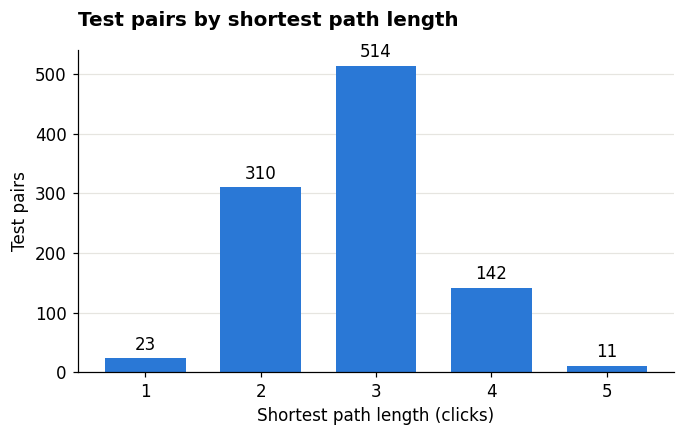

In [27]:
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
})
STYLE = {
    NAME_BFS: dict(color="#8b8a85", marker="x", linestyle="--"),
    NAME_BI: dict(color="#2a78d6", marker="o", linestyle="-"),
    NAME_A0: dict(color="#eb6834", marker="s", linestyle="-"),
    NAME_AL: dict(color="#1baf7a", marker="^", linestyle="-"),
    NAME_C1: dict(color="#eda100", marker="D", linestyle="-"),
    NAME_CW: dict(color="#e87ba4", marker="v", linestyle="-"),
}

def save(fig, name):
    fig.savefig(FIGURES_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    fig.savefig(FIGURES_DIR / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

MIN_PAIRS = 20
plot_data = by_distance[by_distance.pairs >= MIN_PAIRS]
distances = sorted(plot_data.true_distance.unique())

def line_chart(column, ylabel, title, name):
    fig, ax = plt.subplots(figsize=(8, 4.8))
    for algo in algorithms:
        part = plot_data[plot_data.algorithm == algo].sort_values("true_distance")
        ax.plot(part.true_distance, part[column], label=algo, linewidth=2, markersize=7, **STYLE[algo])
    ax.set_yscale("log")
    ax.set_xticks(distances)
    ax.set_xlabel("Shortest path length (clicks)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, pad=62)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=10)
    save(fig, name)

fig, ax = plt.subplots(figsize=(7, 3.8))
bars = ax.bar(distance_table.index, distance_table.values, color="#2a78d6", width=0.7)
ax.bar_label(bars, padding=3)
ax.grid(axis="x", visible=False)
ax.set_xticks(distance_table.index)
ax.set_xlabel("Shortest path length (clicks)")
ax.set_ylabel("Test pairs")
ax.set_title("Test pairs by shortest path length", pad=16)
save(fig, "fig1_test_pair_distances")

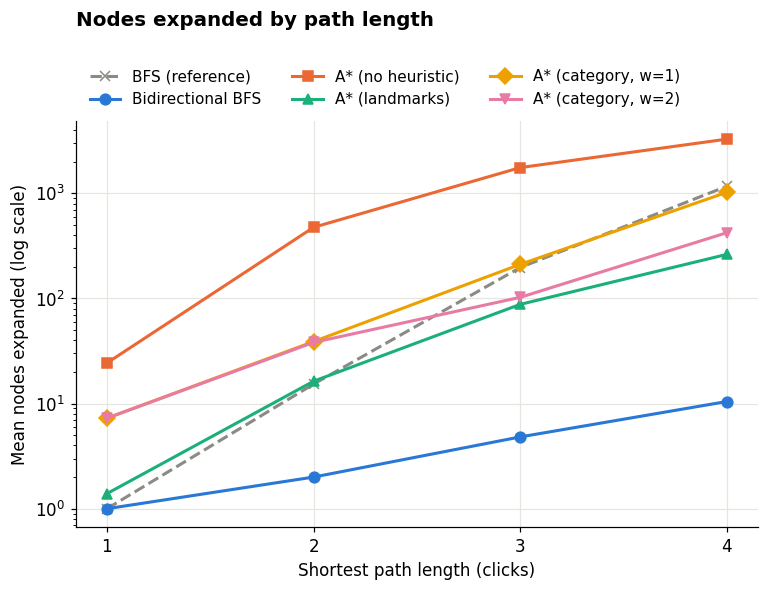

In [28]:
line_chart("mean_expanded", "Mean nodes expanded (log scale)", "Nodes expanded by path length", "fig2_nodes_expanded_by_distance")

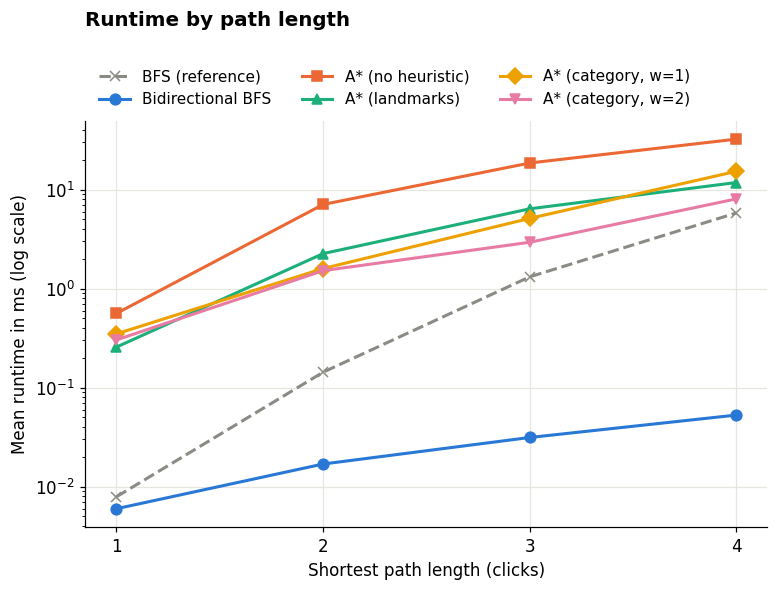

In [29]:
line_chart("mean_time_ms", "Mean runtime in ms (log scale)", "Runtime by path length", "fig3_runtime_by_distance")

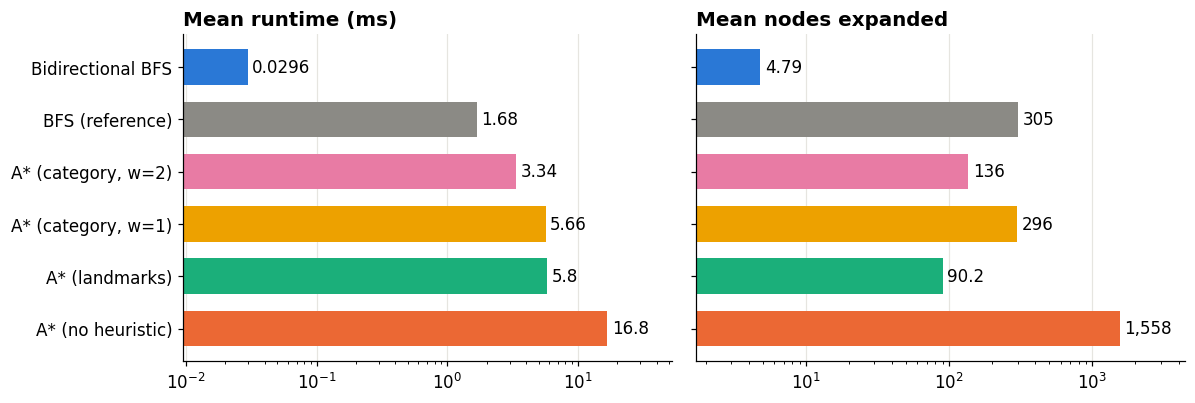

In [30]:
order = summary.sort_values("mean_time_ms").index
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, column, title in ((axes[0], "mean_time_ms", "Mean runtime (ms)"), (axes[1], "mean_expanded", "Mean nodes expanded")):
    colors = [STYLE[a]["color"] for a in order]
    bars = ax.barh(list(order), summary.loc[order, column], color=colors, height=0.68)
    labels = [f"{v:,.0f}" if column == "mean_expanded" and v >= 100 else f"{v:.3g}" for v in summary.loc[order, column]]
    ax.bar_label(bars, labels=labels, padding=3)
    ax.set_xscale("log")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    ax.margins(x=0.18)
axes[0].invert_yaxis()
fig.tight_layout()
save(fig, "fig4_algorithm_overview")

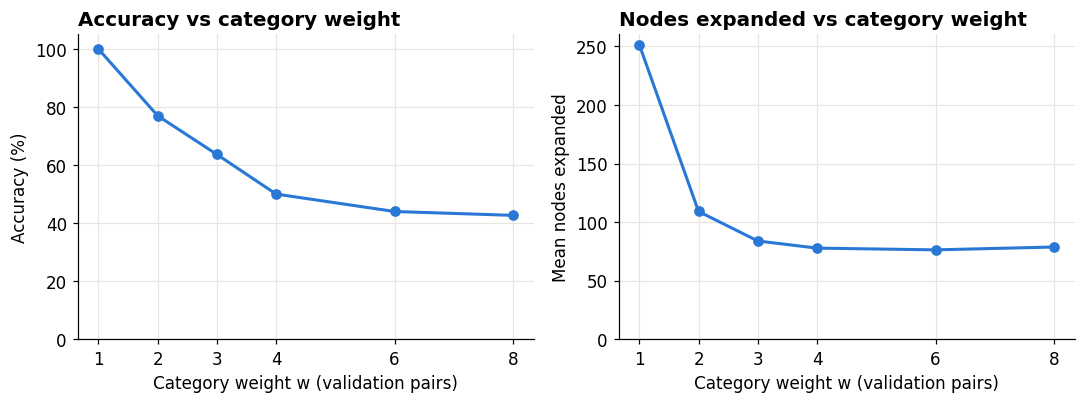

In [31]:
weights = sweep[sweep.heuristic == "category"].sort_values("w")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].plot(weights.w, weights.accuracy_pct, color="#2a78d6", marker="o", linewidth=2)
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy vs category weight")
axes[1].plot(weights.w, weights.mean_expanded, color="#2a78d6", marker="o", linewidth=2)
axes[1].set_ylim(bottom=0)
axes[1].set_ylabel("Mean nodes expanded")
axes[1].set_title("Nodes expanded vs category weight")
for ax in axes:
    ax.set_xlabel("Category weight w (validation pairs)")
    ax.set_xticks(weights.w)
fig.tight_layout()
save(fig, "fig5_category_weight_tradeoff")

## 11. Summary

In [32]:
s = summary
speedup = s.loc[NAME_BFS, "mean_time_ms"] / s.loc[NAME_BI, "mean_time_ms"]
node_saving = s.loc[NAME_BFS, "mean_expanded"] / s.loc[NAME_BI, "mean_expanded"]
landmark_saving = s.loc[NAME_A0, "mean_expanded"] / s.loc[NAME_AL, "mean_expanded"]
TOTAL_SECONDS = time.perf_counter() - NOTEBOOK_START

print(f"1. Bidirectional BFS: {s.loc[NAME_BI, 'accuracy_pct']:.1f}% accuracy, {s.loc[NAME_BI, 'mean_time_ms']:.3f} ms per query, "
      f"{speedup:.0f}x faster than BFS and {node_saving:.0f}x fewer nodes expanded.")
print(f"2. A* with no heuristic: {s.loc[NAME_A0, 'mean_expanded']:.0f} nodes expanded vs {s.loc[NAME_BFS, 'mean_expanded']:.0f} for BFS, "
      f"{s.loc[NAME_A0, 'mean_time_ms']:.2f} ms per query.")
print(f"3. A* with landmarks: {s.loc[NAME_AL, 'accuracy_pct']:.1f}% accuracy, {landmark_saving:.1f}x fewer nodes than A* with no heuristic, "
      f"{s.loc[NAME_AL, 'mean_time_ms']:.2f} ms per query, {s.loc[NAME_AL, 'setup_s']:.2f} s setup.")
print(f"4. Category heuristic: w=1 gave {s.loc[NAME_C1, 'accuracy_pct']:.1f}% accuracy with {s.loc[NAME_C1, 'mean_expanded']:.0f} nodes. "
      f"w={RISKY_W} gave {s.loc[NAME_CW, 'accuracy_pct']:.1f}% with {s.loc[NAME_CW, 'mean_expanded']:.0f} nodes, "
      f"{s.loc[NAME_CW, 'mean_extra_clicks']:.2f} extra clicks on average.")
print(f"5. Human players: {HUMAN_CLICKS:.2f} clicks on average vs {SHORTEST_MEAN:.2f} for the shortest paths.")
print(f"6. Unreachable pairs: every algorithm reported no path on {unreachable.correctly_reported_no_path_pct.min():.0f}% of them.")
print(f"\nTotal run time: {TOTAL_SECONDS:.1f} s (data loading {LOAD_SECONDS:.2f} s, final experiment {EXPERIMENT_SECONDS:.1f} s)")

pd.Series({"total_seconds": TOTAL_SECONDS, "load_seconds": LOAD_SECONDS,
           "experiment_seconds": EXPERIMENT_SECONDS}).to_csv(RESULTS_DIR / "run_time.csv", header=["value"])

1. Bidirectional BFS: 100.0% accuracy, 0.030 ms per query, 57x faster than BFS and 64x fewer nodes expanded.
2. A* with no heuristic: 1558 nodes expanded vs 305 for BFS, 16.79 ms per query.
3. A* with landmarks: 100.0% accuracy, 17.3x fewer nodes than A* with no heuristic, 5.80 ms per query, 0.67 s setup.
4. Category heuristic: w=1 gave 100.0% accuracy with 296 nodes. w=2 gave 81.3% with 136 nodes, 0.19 extra clicks on average.
5. Human players: 5.32 clicks on average vs 2.81 for the shortest paths.
6. Unreachable pairs: every algorithm reported no path on 100% of them.

Total run time: 4684.1 s (data loading 1.01 s, final experiment 324.7 s)


In [33]:
import shutil
from google.colab import files

shutil.make_archive(str(ROOT / "results"), "zip", RESULTS_DIR)
files.download(str(ROOT / "results.zip"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

Bidirectional BFS was the best method for exact shortest paths on this graph. It was always correct, needed no setup and was the fastest method tested. Paths in Wikispeedia are short and hub articles make the search grow quickly, so meeting in the middle saves the most work.

A* depends heavily on its heuristic. With no heuristic it expanded more nodes than BFS. The landmark heuristic reduced the nodes expanded while keeping every path optimal, but computing it made each search slower than plain BFS. The category heuristic with w = 2 searched less but returned a longer path on some pairs, which shows the trade-off of an inadmissible heuristic.

The test pairs come from human games, so they reflect how the game chose articles. Runtimes depend on the machine, while accuracy and nodes expanded are fixed by the random seed.

## References

1. R. West and J. Leskovec. Human Wayfinding in Information Networks. WWW, 2012.
2. R. West, J. Pineau and D. Precup. Wikispeedia: An Online Game for Inferring Semantic Distances between Concepts. IJCAI, 2009.
3. A. V. Goldberg and C. Harrelson. Computing the Shortest Path: A* Search Meets Graph Theory. SODA, 2005.